In [15]:

# Install required libraries
!pip install librosa soundfile -q

# Import necessary libraries
import os
import zipfile
import librosa
import librosa.display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import files

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:

# Upload the ZIP file containing the voice dataset
uploaded = files.upload()

# Extract the uploaded ZIP file
zip_file = next(iter(uploaded.keys()))

extract_path = "/content/voice_dataset"

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")


Saving VOICE DATASET.zip to VOICE DATASET.zip
Dataset extracted successfully!


In [3]:

# Define dataset folders
base_path = Path(extract_path)

# Find the boys and girls folders
boys_folder = next(
    p for p in base_path.rglob("*")
    if p.is_dir() and p.name.upper() == "VOICE DATASET BOYS"
)

girls_folder = next(
    p for p in base_path.rglob("*")
    if p.is_dir() and p.name.upper() == "VOICE DATASET GIRLS"
)

# Supported audio formats
audio_extensions = {
    '.wav', '.mp3', '.ogg', '.flac', '.m4a', '.aac', '.wma'
}

# Collect audio files from each class
boys_files = [
    f for f in boys_folder.rglob("*")
    if f.is_file() and f.suffix.lower() in audio_extensions
]

girls_files = [
    f for f in girls_folder.rglob("*")
    if f.is_file() and f.suffix.lower() in audio_extensions
]

# Count the recordings
print("BOYS AUDIO FILES:", len(boys_files))
print("GIRLS AUDIO FILES:", len(girls_files))
print("TOTAL AUDIO FILES:", len(boys_files) + len(girls_files))


BOYS AUDIO FILES: 124
GIRLS AUDIO FILES: 19
TOTAL AUDIO FILES: 143


In [4]:

# Create an empty list to store audio information
audio_data = []

# Combine both classes
all_files = (
    [(f, "Boys") for f in boys_files] +
    [(f, "Girls") for f in girls_files]
)

# Read each audio file and extract its properties
for file_path, label in all_files:

    try:
        # Load audio without changing the original sampling rate
        signal, sr = librosa.load(file_path, sr=None)

        # Calculate audio duration
        duration = len(signal) / sr

        # Store file information
        audio_data.append({
            "File Name": file_path.name,
            "Class": label,
            "Sampling Rate (Hz)": sr,
            "Duration (seconds)": round(duration, 2),
            "File Format": file_path.suffix.lower()
        })

    except Exception as e:
        print("Error loading:", file_path.name, e)

# Convert collected information into a DataFrame
df = pd.DataFrame(audio_data)

# Display information for every audio file
display(df)

# Display summary statistics
print("\nDATASET SUMMARY")
print("---------------------------")

print("\nSampling Rate Statistics:")
print(df["Sampling Rate (Hz)"].describe())

print("\nDuration Statistics:")
print(df["Duration (seconds)"].describe())

print("\nFile Format Distribution:")
print(df["File Format"].value_counts())


/tmp/ipykernel_436/2023964021.py:15: UserWarning: PySoundFile failed. Trying audioread instead.
  signal, sr = librosa.load(file_path, sr=None)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


,File Name,Class,Sampling Rate (Hz),Duration (seconds),File Format
0,Aryan Raj_BIT.wav,Boys,48000,3.50,.wav
1,AOZZ_BRAHMSHIV_JHA_BIT.wav,Boys,48000,0.85,.wav
2,Karan_BIT.wav,Boys,48000,0.90,.wav
3,Abhishek_Name_trimmed.wav,Boys,48000,0.89,.wav
4,Yash_Gupta_Name.wav,Boys,48000,1.96,.wav
...,...,...,...,...,...
138,Qamareen_BIT.wav,Girls,48000,0.97,.wav
139,Shreya_BIT.mp3,Girls,48000,2.65,.mp3
140,Preksha_Name.wav,Girls,16000,2.15,.wav
141,Avantika_BIT.wav,Girls,48000,2.79,.wav



DATASET SUMMARY
---------------------------

Sampling Rate Statistics:
count      143.000000
mean     44417.482517
std       8516.364237
min      16000.000000
25%      44100.000000
50%      48000.000000
75%      48000.000000
max      48000.000000
Name: Sampling Rate (Hz), dtype: float64

Duration Statistics:
count    143.000000
mean       2.627832
std        1.694292
min        0.460000
25%        1.325000
50%        2.150000
75%        3.520000
max       10.200000
Name: Duration (seconds), dtype: float64

File Format Distribution:
File Format
.wav    115
.mp3     27
.m4a      1
Name: count, dtype: int64


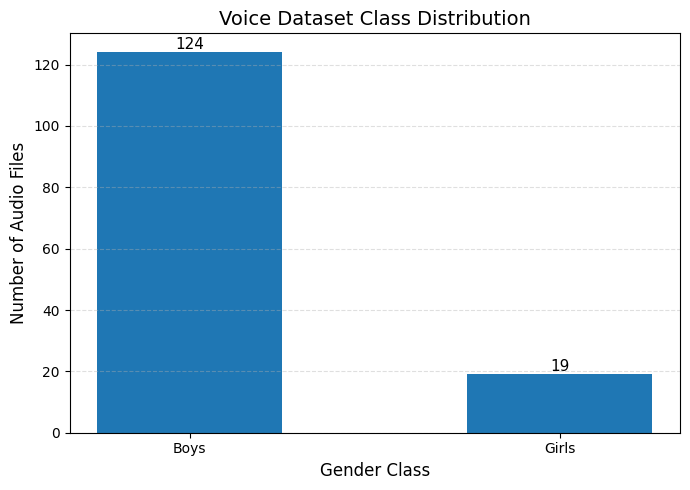

In [5]:

# Calculate the number of recordings in each class
class_counts = df["Class"].value_counts()

# Plot class distribution
plt.figure(figsize=(7, 5))

plt.bar(
    class_counts.index,
    class_counts.values,
    width=0.5
)

plt.xlabel("Gender Class", fontsize=12)
plt.ylabel("Number of Audio Files", fontsize=12)
plt.title("Voice Dataset Class Distribution", fontsize=14)

# Display sample counts above bars
for i, value in enumerate(class_counts.values):
    plt.text(i, value, str(value),
             ha='center', va='bottom', fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


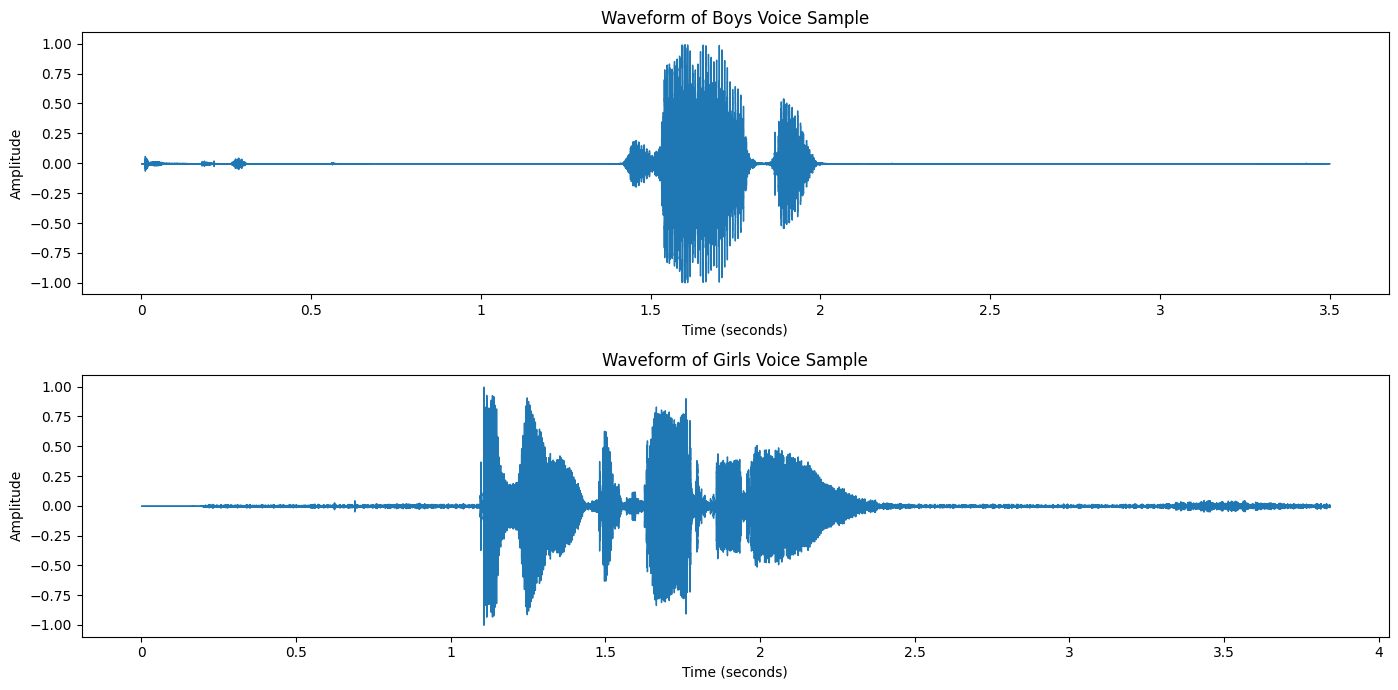

In [6]:

# Select one audio sample from each class
boy_sample = boys_files[0]
girl_sample = girls_files[0]

# Load audio signals
boy_audio, boy_sr = librosa.load(boy_sample, sr=None)
girl_audio, girl_sr = librosa.load(girl_sample, sr=None)

# Create two waveform plots
plt.figure(figsize=(14, 7))

# Boys waveform
plt.subplot(2, 1, 1)

librosa.display.waveshow(
    boy_audio,
    sr=boy_sr
)

plt.title("Waveform of Boys Voice Sample")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

# Girls waveform
plt.subplot(2, 1, 2)

librosa.display.waveshow(
    girl_audio,
    sr=girl_sr
)

plt.title("Waveform of Girls Voice Sample")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()


In [7]:

# Lists to store MFCC features and corresponding labels
X = []
y = []

# Extract MFCC features from all audio files
for file_path, label in all_files:

    try:
        # Load audio
        signal, sr = librosa.load(file_path, sr=None)

        # Extract 13 MFCC coefficients
        mfcc = librosa.feature.mfcc(
            y=signal,
            sr=sr,
            n_mfcc=13
        )

        # Calculate mean MFCC values
        mfcc_features = np.mean(mfcc, axis=1)

        # Store features and labels
        X.append(mfcc_features)

        # Boys = 0, Girls = 1
        y.append(0 if label == "Boys" else 1)

    except Exception as e:
        print("MFCC extraction error:", file_path.name, e)

# Convert into NumPy arrays
X = np.array(X)
y = np.array(y)

print("MFCC Feature Matrix Shape:", X.shape)
print("Label Array Shape:", y.shape)
print("MFCC Extraction Completed!")


/tmp/ipykernel_436/4210080714.py:10: UserWarning: PySoundFile failed. Trying audioread instead.
  signal, sr = librosa.load(file_path, sr=None)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


MFCC Feature Matrix Shape: (143, 13)
Label Array Shape: (143,)
MFCC Extraction Completed!


In [8]:

# Initialize feature and label lists
features = []
labels = []
filenames = []

# Combine boys and girls audio files
all_files = (
    [(f, 1) for f in boys_files] +
    [(f, 2) for f in girls_files]
)

# Extract MFCC features from every audio file
for file_path, label in all_files:

    try:
        # Load audio at a common sampling rate
        signal, sr = librosa.load(file_path, sr=22050)

        # Extract 13 MFCC coefficients
        mfcc = librosa.feature.mfcc(
            y=signal,
            sr=sr,
            n_mfcc=13
        )

        # Calculate mean and standard deviation
        mfcc_mean = np.mean(mfcc, axis=1)
        mfcc_std = np.std(mfcc, axis=1)

        # Combine into a 26-dimensional feature vector
        feature_vector = np.concatenate([mfcc_mean, mfcc_std])

        features.append(feature_vector)
        labels.append(label)
        filenames.append(file_path.name)

    except Exception as e:
        print("Error:", file_path.name, e)

# Convert into NumPy arrays
X = np.array(features)
y = np.array(labels)

print("Feature Matrix Shape:", X.shape)
print("Label Array Shape:", y.shape)
print("Feature Extraction Completed!")


/tmp/ipykernel_436/63200920.py:17: UserWarning: PySoundFile failed. Trying audioread instead.
  signal, sr = librosa.load(file_path, sr=22050)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Feature Matrix Shape: (143, 26)
Label Array Shape: (143,)
Feature Extraction Completed!


In [9]:

# Create feature column names
mean_columns = [f"MFCC{i}_Mean" for i in range(1, 14)]
std_columns = [f"MFCC{i}_Std" for i in range(1, 14)]

columns = mean_columns + std_columns

# Create DataFrame
df = pd.DataFrame(X, columns=columns)

# Add filename and class labels
df.insert(0, "Filename", filenames)
df["Class"] = y

# Save as CSV
csv_path = "/content/MFCC_Gender_Features.csv"
df.to_csv(csv_path, index=False)

print("CSV file saved successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

# Download CSV
files.download(csv_path)


CSV file saved successfully!
Dataset Shape: (143, 28)


,Filename,MFCC1_Mean,MFCC2_Mean,MFCC3_Mean,MFCC4_Mean,MFCC5_Mean,MFCC6_Mean,MFCC7_Mean,MFCC8_Mean,MFCC9_Mean,...,MFCC5_Std,MFCC6_Std,MFCC7_Std,MFCC8_Std,MFCC9_Std,MFCC10_Std,MFCC11_Std,MFCC12_Std,MFCC13_Std,Class
0,Aryan Raj_BIT.wav,-480.376923,30.557423,0.972080,18.571344,9.125403,-0.427973,-3.098021,0.191158,-1.689537,...,20.290123,11.467997,12.953286,7.565885,7.817857,7.477358,6.698884,4.939814,5.223318,1
1,AOZZ_BRAHMSHIV_JHA_BIT.wav,-180.468979,94.500679,22.686113,62.304569,27.066473,-10.227566,-9.462534,0.441756,-21.619871,...,19.576059,19.746698,20.186165,12.465970,12.030015,18.313221,8.944097,7.948096,11.306512,1
2,Karan_BIT.wav,-296.505859,149.175323,-16.812042,31.383110,-24.997705,10.650357,-1.752832,6.646725,0.333576,...,13.387825,12.623267,6.807379,7.462958,5.559174,8.757875,7.515413,5.796896,6.095231,1
3,Abhishek_Name_trimmed.wav,-274.225830,146.441437,35.588711,13.656890,-21.681652,14.829205,-19.192558,6.018180,-16.884045,...,29.222145,9.769564,12.795138,8.954222,7.043526,8.031587,14.849283,10.883840,6.734657,1
4,Yash_Gupta_Name.wav,-332.175049,105.276985,8.299267,28.473915,-5.083821,2.315266,-1.662191,-3.866802,-11.626447,...,29.749704,28.282721,13.398421,14.857299,14.389826,10.834418,11.369719,9.528837,7.921871,1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

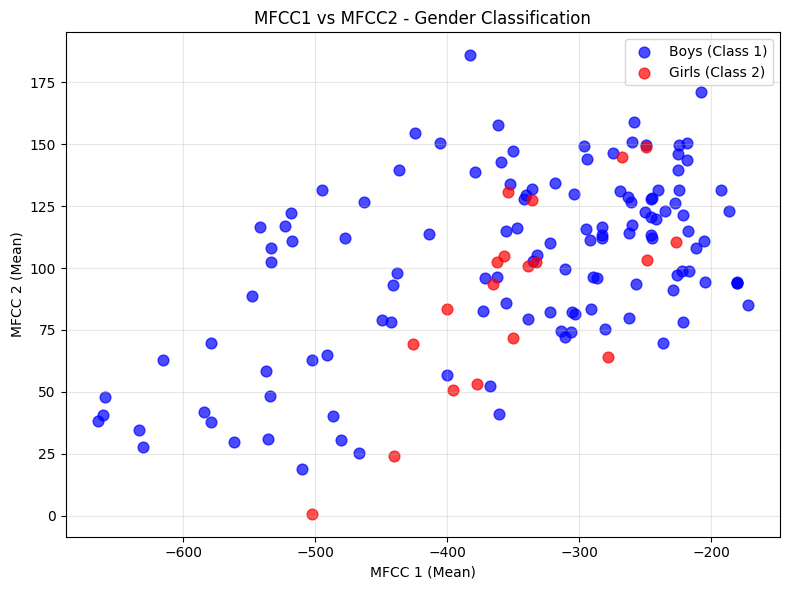

In [10]:

# Extract first two mean MFCC coefficients
mfcc1 = X[:, 0]
mfcc2 = X[:, 1]

# Create scatter plot
plt.figure(figsize=(8, 6))

# Boys samples
plt.scatter(
    mfcc1[y == 1],
    mfcc2[y == 1],
    color='blue',
    label='Boys (Class 1)',
    alpha=0.7,
    s=60
)

# Girls samples
plt.scatter(
    mfcc1[y == 2],
    mfcc2[y == 2],
    color='red',
    label='Girls (Class 2)',
    alpha=0.7,
    s=60
)

plt.xlabel("MFCC 1 (Mean)")
plt.ylabel("MFCC 2 (Mean)")
plt.title("MFCC1 vs MFCC2 - Gender Classification")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
# Standardize all 26 MFCC features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reduce 26 dimensions to 2 using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Display explained variance
variance = pca.explained_variance_ratio_

print("PCA Shape:", X_pca.shape)
print("PC1 Variance:", round(variance[0] * 100, 2), "%")
print("PC2 Variance:", round(variance[1] * 100, 2), "%")
print("Total Variance:", round(sum(variance) * 100, 2), "%")


PCA Shape: (143, 2)
PC1 Variance: 22.07 %
PC2 Variance: 11.24 %
Total Variance: 33.32 %


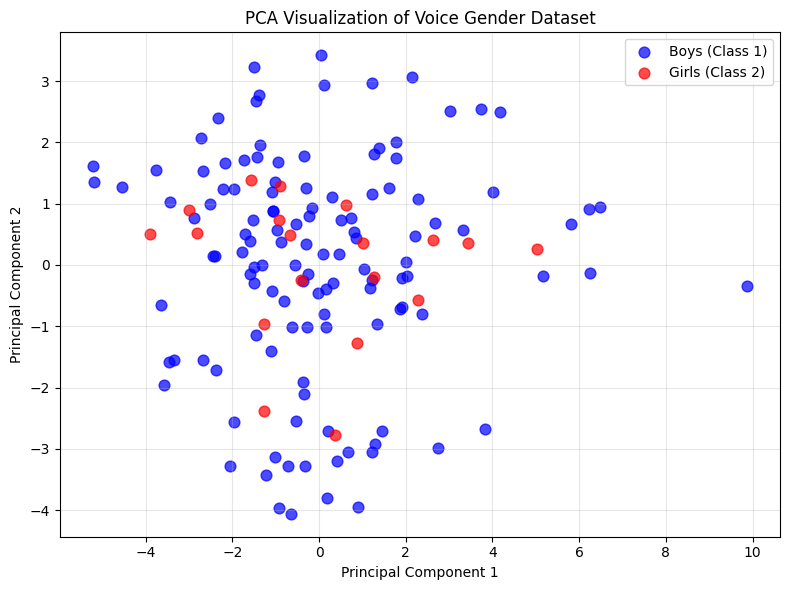

In [17]:

# Plot PCA results
plt.figure(figsize=(8, 6))

# Boys samples
plt.scatter(
    X_pca[y == 1, 0],
    X_pca[y == 1, 1],
    color='blue',
    label='Boys (Class 1)',
    alpha=0.7,
    s=60
)

# Girls samples
plt.scatter(
    X_pca[y == 2, 0],
    X_pca[y == 2, 1],
    color='red',
    label='Girls (Class 2)',
    alpha=0.7,
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Voice Gender Dataset")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
